In [53]:
'''2:
Distanza (Knorr, KNN (Ramaswamy / Pizzuti / ln-degree))
Densità (LOF, COF, INFLO)
Clustering (CBLOF)'''

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform

In [54]:
df = pd.read_csv("df.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

train_imputed_rf = pd.read_csv("train_imputed_rf.csv")
test_imputed_rf = pd.read_csv("test_imputed_rf.csv")

tt = np.concatenate([train_imputed, test_imputed], axis=0)

df_unito = pd.DataFrame(tt, columns=train_imputed.columns)



In [55]:
# come conviene gestire le stagioni? trasformarle in 1234 non ha senso in questo caso
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

X=df_unito.values
y=np.array(df_unito['sii'])
X_standard=standard_scaler.fit_transform(X)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(X_standard, y, test_size=0.3, random_state=0)

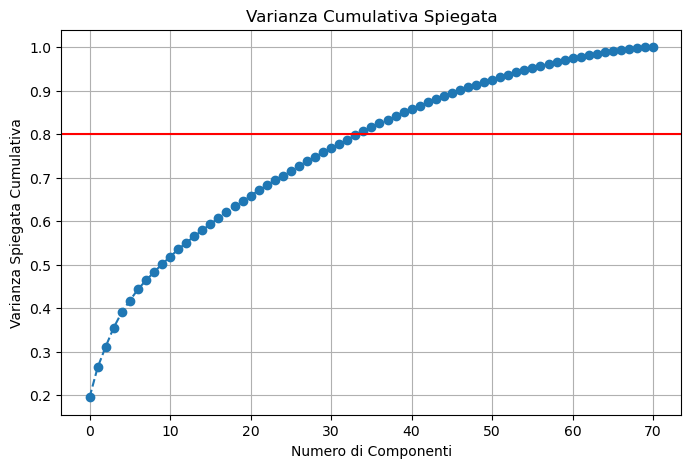

In [56]:
# Calcoliamo la PCA su tutte le componenti possibili per vedere il quadro completo
pca_full = PCA().fit(X_standard)
plt.figure(figsize=(8, 5))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o', linestyle='--')
plt.axhline(y=0.8, color='r', linestyle='-') # Linea del 80%
plt.title('Varianza Cumulativa Spiegata')
plt.xlabel('Numero di Componenti')
plt.ylabel('Varianza Spiegata Cumulativa')
plt.grid()
plt.show()

#quindi praticamente inutile

In [57]:
from sklearn.metrics import roc_auc_score

# Supponiamo che 0 sia la classe 'Normale'
classi_anomale = [c for c in np.unique(y) if c != 0]

for k_test in [5, 10, 20, 50, 100]:
    model = KNN(n_neighbors=k_test)
    model.fit(X) 
    score = model.decision_scores_
    
    print(f"\n--- Risultati per k={k_test} ---")
    
    for c in classi_anomale:
        # Creiamo un target temporaneo: Classe 0 vs Classe specifica 'c'
        mask = (y == 0) | (y == c)
        y_temp = y[mask]
        score_temp = score[mask]
        
        # Binarizziamo solo per questo confronto (0 vs c)
        y_temp_bin = (y_temp == c).astype(int)
        
        auc = roc_auc_score(y_temp_bin, score_temp)
        print(f"Classe {c} vs Normale: AUC = {auc:.4f}")


--- Risultati per k=5 ---
Classe 1 vs Normale: AUC = 0.6003
Classe 2 vs Normale: AUC = 0.6674
Classe 3 vs Normale: AUC = 0.5668

--- Risultati per k=10 ---
Classe 1 vs Normale: AUC = 0.5963
Classe 2 vs Normale: AUC = 0.6618
Classe 3 vs Normale: AUC = 0.5677

--- Risultati per k=20 ---
Classe 1 vs Normale: AUC = 0.5930
Classe 2 vs Normale: AUC = 0.6541
Classe 3 vs Normale: AUC = 0.5643

--- Risultati per k=50 ---
Classe 1 vs Normale: AUC = 0.5877
Classe 2 vs Normale: AUC = 0.6442
Classe 3 vs Normale: AUC = 0.5569

--- Risultati per k=100 ---
Classe 1 vs Normale: AUC = 0.5821
Classe 2 vs Normale: AUC = 0.6367
Classe 3 vs Normale: AUC = 0.5484


KNN(algorithm='auto', contamination=0.01, leaf_size=30, method='mean',
  metric='minkowski', metric_params=None, n_jobs=1, n_neighbors=10, p=2,
  radius=1.0)


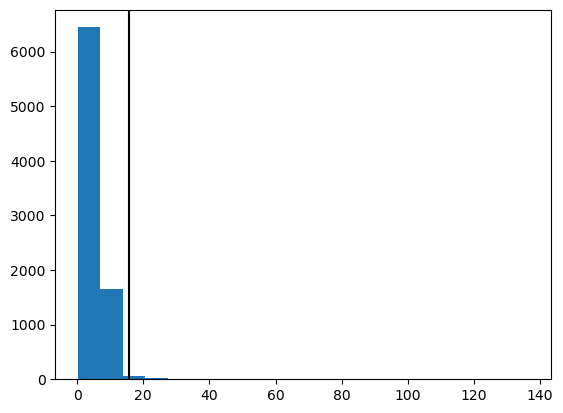

Numero di outlier trovati: 58 (0.71%)


In [58]:
#=====KNN======
'''General models
• Take the kNN distance of a point as its outlier score [Ramaswamy et al 2000]
• Aggregate the distances of a point to all its 1NN, 2NN, …, kNN as an outlier
score [Angiulli and Pizzuti 2002]'''

#n=round(m.sqrt(len(df_unito)))
n=10
clf = KNN(contamination=0.01, n_neighbors=n, method='mean') 
#scritto nella descrizione del metodo e consigliato da guidotti: 'mean': use the average of all k neighbors as the outlier score

print(clf.fit(X_standard))

outliers_knn = clf.predict(X_standard)
np.unique(outliers_knn, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_knn==1)]), c='k')
plt.show()

n_outliers_knn = np.sum(outliers_knn)
print(f"Numero di outlier trovati: {int(n_outliers_knn)} ({n_outliers_knn/len(df_unito)*100:.2f}%)")

#1% di outliers come scritto nelle slide (contamination)

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_1603/3420767338.py:22: DeprecationWarning: Calling nonzero on 0d arrays is deprecated, as it behaves surprisingly. Use `atleast_1d(cond).nonzero()` if the old behavior was intended. If the context of this warning is of the form `arr[nonzero(cond)]`, just use `arr[cond]`.
  plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')


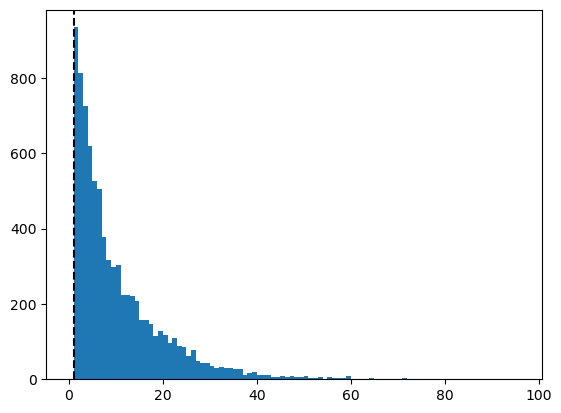

Numero di outlier trovati: 934 (11.41%)


In [59]:
#=====RKNN======
# 1. Trova i k-vicini per ogni punto
k = 10
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)

# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out= np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_unito)*100:.2f}%)")
#molto in dubbio. mi da 11% di outliers pur impostando 1. secondo gemini molti valori tutti uguali e quindi si arriva all'11


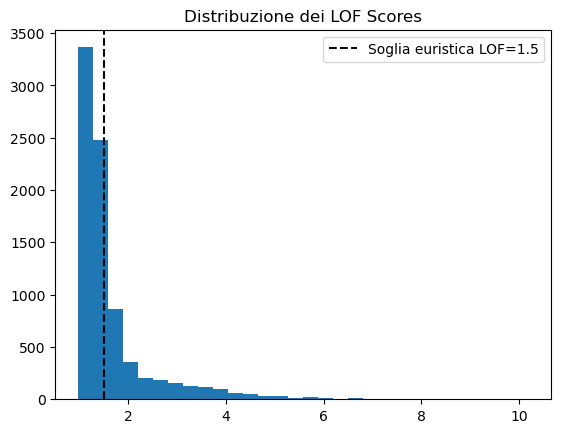

Numero di outlier trovati: 323273 (3950.06%)


In [60]:
# ==== ## LOF (sklearn) ====
from sklearn.neighbors import LocalOutlierFactor

'''PRESO DA SKLEARN: By default, LocalOutlierFactor is only meant to be used for outlier detection (
novelty=False). Set novelty to True if you want to use LocalOutlierFactor for 
novelty detection. In this case be aware that you should only use predict, 
decision_function and score_samples on new unseen data and not on the training 
set; and note that the results obtained this way may differ from the standard LOF 
results'''
# Parametri: n_neighbors solitamente > 10-20 per avere una stima stabile della densità
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01, novelty=False)

# Con novelty=False si usa fit_predict
y_pred_lof = lof.fit_predict(X_standard) 

# Gli score sono negativi (più sono bassi, più è outlier)
# Li invertiamo per averli positivi (LOF > 1 indica potenziale outlier)
lof_scores = -lof.negative_outlier_factor_

# Identifichiamo gli indici degli outlier (y_pred == -1)

outliers_lof_idx = np.where(y_pred_lof == -1)

plt.hist(lof_scores, bins=30)
#non si capisce bene come vada scelto il limite
plt.axvline(x=1.5, color='black', linestyle='--', label='Soglia euristica LOF=1.5') 
#plt.hist(clf.negative_outlier_factor_, bins=20)
#plt.axvline(np.min(clf.negative_outlier_factor_[np.where(outliers==1)]), c='k')# Tipico valore soglia
plt.title("Distribuzione dei LOF Scores")
plt.legend()
plt.show()

n_outliers_lof = np.sum(outliers_lof_idx)
print(f"Numero di outlier trovati: {int(n_outliers_lof)} ({n_outliers_lof/len(df_unito)*100:.2f}%)")

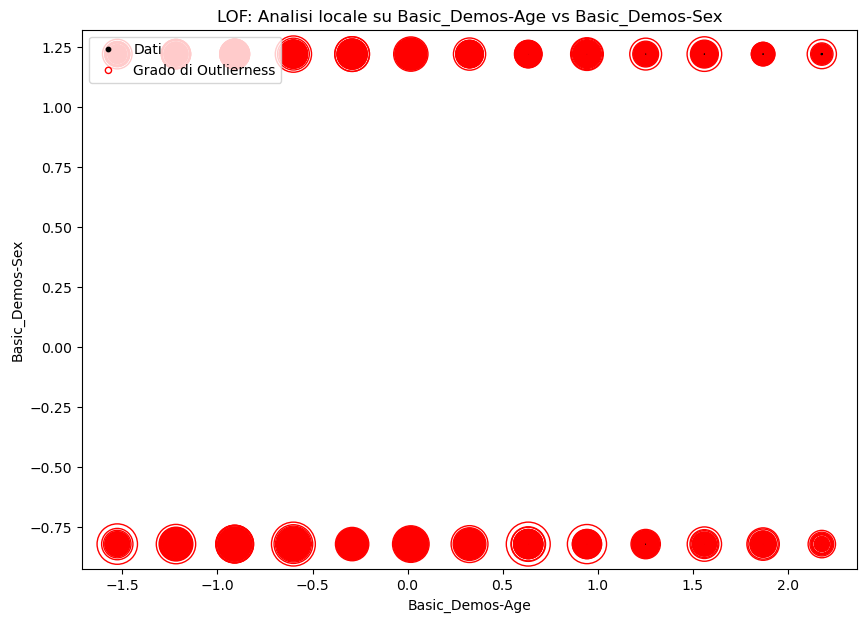

Outlier rilevati (spazio totale): 82


In [61]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor

# 1. Preparazione dati
X_to_plot = X_standard 

# Invece della PCA, scegliamo due indici di colonne che consideri interessanti
# Es: 0 per l'età e 4 per un punteggio clinico (controlla i nomi nel tuo df)
idx_x = 0 
idx_y = 1 

# Estraiamo i nomi delle feature per gli assi (se hai il dataframe originale)
feat_name_x = df_unito.columns[idx_x]
feat_name_y = df_unito.columns[idx_y]

# 2. Fit del Modello (Il calcolo avviene comunque su TUTTE le N feature)
n_neighbors = 20
contamination = 0.01
clf = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)

# fit_predict calcola la densità nello spazio multidimensionale completo
y_pred = clf.fit_predict(X_to_plot)

# 3. Calcolo degli Score per la visualizzazione
X_scores = clf.negative_outlier_factor_

# 4. Plot
plt.figure(figsize=(10, 7))
plt.title(f"LOF: Analisi locale su {feat_name_x} vs {feat_name_y}")

# Usiamo direttamente le colonne scelte per lo scatter
plt.scatter(X_to_plot[:, idx_x], X_to_plot[:, idx_y], color='k', s=3., label='Dati')

# Disegniamo i cerchi rossi proporzionali all'outlierness
# Il raggio è calcolato in base allo score ottenuto nello spazio a N-dimensioni
radius = (X_scores.max() - X_scores) / (X_scores.max() - X_scores.min())

plt.scatter(X_to_plot[:, idx_x], X_to_plot[:, idx_y], s=1000 * radius, 
            edgecolors='r', facecolors='none', label='Grado di Outlierness')

plt.axis('tight')
plt.xlabel(feat_name_x)
plt.ylabel(feat_name_y)
legend = plt.legend(loc='upper left')
legend.legend_handles[0]._sizes = [10]
legend.legend_handles[1]._sizes = [20]
plt.show()

n_outliers_detected = (y_pred == -1).sum()
print(f"Outlier rilevati (spazio totale): {n_outliers_detected}")

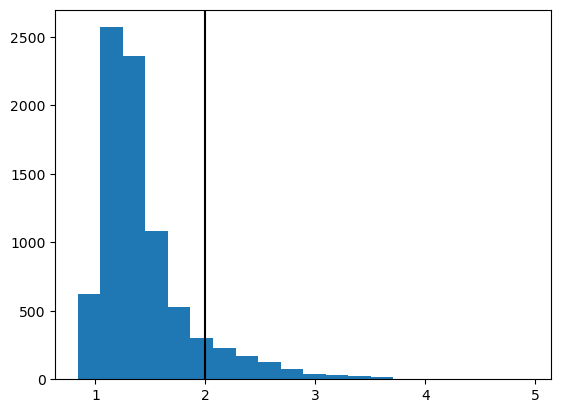

Numero di outlier trovati: 819 (10.01%)


In [62]:
#==== COF ====
from pyod.models.cof import COF
clf = COF(contamination=0.1, method='fast', n_neighbors=20)
clf.fit(X_standard)

outliers_cof = clf.predict(X_standard)
#np.unique(outliers_cof, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_cof==1)]), c='k')
plt.show()

n_outliers_cof = np.sum(outliers_cof)
print(f"Numero di outlier trovati: {int(n_outliers_cof)} ({n_outliers_cof/len(df_unito)*100:.2f}%)")

In [63]:
#==== DBSCAN non è che sia incredibile====

from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=5, min_samples=10)
dbscan.fit(X_standard)

#np.unique(dbscan.labels_, return_counts=True)

df.loc[np.where(dbscan.labels_==-1)]

,Basic_Demos-Enroll_Season,Basic_Demos-Age,Basic_Demos-Sex,CGAS-Season,CGAS-CGAS_Score,Physical-Season,Physical-BMI,Physical-Height,Physical-Weight,Physical-Waist_Circumference,...,PCIAT-PCIAT_19,PCIAT-PCIAT_20,PCIAT-PCIAT_Total,SDS-Season,SDS-SDS_Total_Raw,SDS-SDS_Total_T,PreInt_EduHx-Season,PreInt_EduHx-computerinternet_hoursday,sii,Fitness_Endurance-Tempo_totale
0,Fall,5,0,Winter,51.0,Fall,16.877316,46.00,50.8,26.0,...,2.0,4.0,55.0,NaN,NaN,NaN,Fall,3.0,2.0,448.0
3,Winter,9,0,Fall,71.0,Summer,18.292347,56.00,81.6,26.0,...,4.0,1.0,44.0,Summer,31.0,45.0,Winter,0.0,1.0,577.0
5,Fall,10,0,Spring,NaN,Fall,19.660760,55.00,84.6,NaN,...,1.0,0.0,20.0,Winter,27.0,40.0,Fall,3.0,0.0,NaN
8,Spring,11,1,Spring,65.0,NaN,NaN,55.00,77.0,26.0,...,NaN,NaN,NaN,NaN,NaN,NaN,Spring,NaN,0.0,NaN
9,Fall,11,0,Summer,66.0,Spring,NaN,55.00,77.0,26.0,...,1.0,0.0,10.0,Winter,42.0,59.0,Fall,0.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8171,Fall,10,0,Spring,84.5,Summer,21.571563,NaN,104.8,28.5,...,NaN,NaN,NaN,Winter,37.0,52.0,Winter,0.0,0.0,477.5
8175,Winter,14,0,Fall,60.5,Fall,22.291181,66.27,123.8,NaN,...,NaN,NaN,NaN,Winter,38.5,51.5,Winter,0.0,1.0,NaN
8177,Fall,12,1,Winter,NaN,Fall,19.713726,NaN,105.7,29.5,...,NaN,NaN,NaN,NaN,NaN,NaN,Fall,2.0,0.0,NaN
8180,Winter,10,1,Spring,69.5,Winter,NaN,56.13,47.8,28.5,...,NaN,NaN,NaN,NaN,NaN,NaN,Winter,0.0,1.0,451.5


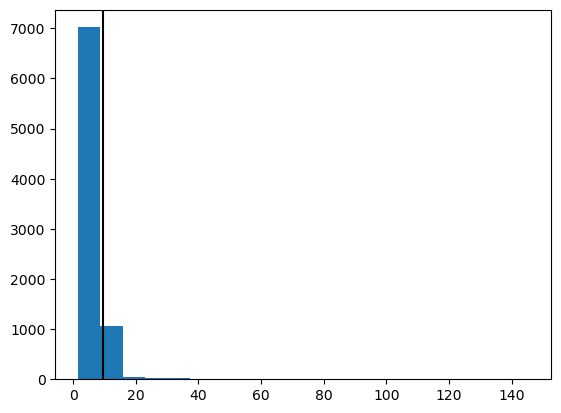

Numero di outlier trovati: 819 (10.01%)


In [64]:
#==== CBLOF ====
from pyod.models.cblof import CBLOF

clf = CBLOF()
clf.fit(X_standard)

outliers_cblof = clf.predict(X_standard)
np.unique(outliers_cblof, return_counts=True)

plt.hist(clf.decision_scores_, bins=20)
plt.axvline(np.min(clf.decision_scores_[np.where(outliers_cblof==1)]), c='k')
plt.show()

n_outliers_cblof = np.sum(outliers_cblof)
print(f"Numero di outlier trovati: {int(n_outliers_cblof)} ({n_outliers_cblof/len(df_unito)*100:.2f}%)")